In [1]:
import joblib
dane = joblib.load('clean_data.pkl')
dane.head()


c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\io\formats\format.py:1466: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,id,name,neighbourhood_group,room_type,price,rating,bedrooms,beds,baths
0,1312228,Rental unit in Brooklyn · ★5.0 · 1 bedroom,Brooklyn,Private room,55.0,5.000000,1,1,NaN
1,45277537,Rental unit in New York · ★4.67 · 2 bedrooms ·...,Manhattan,Entire home/apt,144.0,4.671875,2,1,1.0
2,971353993633883038,Rental unit in New York · ★4.17 · 1 bedroom · ...,Manhattan,Entire home/apt,187.0,4.171875,1,2,1.0
3,3857863,Rental unit in New York · ★4.64 · 1 bedroom · ...,Manhattan,Private room,120.0,4.640625,1,1,1.0
4,40896611,Condo in New York · ★4.91 · Studio · 1 bed · 1...,Manhattan,Entire home/apt,85.0,4.910156,0,1,1.0


In [2]:
dane = dane.dropna(subset = 'baths')

In [3]:
X = dane[['neighbourhood_group','room_type', 'bedrooms','beds','baths']]
y = dane['price']

In [4]:
X.isna().sum()

neighbourhood_group    0
room_type              0
bedrooms               0
beds                   0
baths                  0
dtype: int64

In [5]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state= 42)


In [6]:
len(X_train)


16596

In [7]:
len(X_test)

4149

In [8]:
dane.isna().sum()

id                        0
name                      0
neighbourhood_group       0
room_type                 0
price                     0
rating                 3748
bedrooms                  0
beds                      0
baths                     0
dtype: int64

In [9]:
len(X_test)

4149

In [10]:
len(X_train)

16596

In [11]:
category_columns = ['neighbourhood_group', 'room_type']
numeric_columns = ['bedrooms', 'beds', 'baths']

In [12]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder()
transform_catyegory_columns = encoder.fit_transform(X_train[category_columns])

In [13]:
type(transform_catyegory_columns)

scipy.sparse._csr.csr_matrix

In [14]:
print(transform_catyegory_columns.shape)

(16596, 9)


In [15]:
encoder.categories_

[array(['Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island'],
       dtype=object),
 array(['Entire home/apt', 'Hotel room', 'Private room', 'Shared room'],
       dtype=object)]

In [16]:
encoder.get_feature_names_out(category_columns)

array(['neighbourhood_group_Bronx', 'neighbourhood_group_Brooklyn',
       'neighbourhood_group_Manhattan', 'neighbourhood_group_Queens',
       'neighbourhood_group_Staten Island', 'room_type_Entire home/apt',
       'room_type_Hotel room', 'room_type_Private room',
       'room_type_Shared room'], dtype=object)

In [17]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
preprocessor = ColumnTransformer(transformers=[('num', StandardScaler(), numeric_columns),
                                               ('cat', OneHotEncoder(),category_columns )])

In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
potok1 = Pipeline(steps=[('preprocessor', preprocessor),
                        ('regressor', LinearRegression())])
model_Linear_Regression = potok1.fit(X_train, y_train)

In [19]:
from sklearn.model_selection import cross_validate

wyniki = cross_validate(potok1, X_train, y_train, cv=5, scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error','r2'])
wyniki

{'fit_time': array([0.02389479, 0.02751589, 0.02535152, 0.02516174, 0.02429199]),
 'score_time': array([0.01219153, 0.0100987 , 0.00924444, 0.01056695, 0.00928998]),
 'test_neg_mean_absolute_error': array([-119.74403712,  -96.83625709, -121.91500792,  -95.86719695,
         -97.5869157 ]),
 'test_neg_root_mean_squared_error': array([-1746.34902086,  -303.16673759, -1758.16427114,  -236.89168287,
         -254.24712757]),
 'test_r2': array([0.00163421, 0.09348206, 0.00199948, 0.12643094, 0.1577343 ])}

In [20]:
mae = -wyniki['test_neg_mean_absolute_error'].mean()
rmse = -wyniki['test_neg_root_mean_squared_error'].mean()
r2 = wyniki['test_r2'].mean()
print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 106.38988295605384
RMSE: 859.7637680077187
R2: 0.07625619870940956


In [21]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
potok2 = Pipeline(steps=[('preprocessor', preprocessor),
                        ('regressor', RandomForestRegressor())])
model_Random_Forest = potok2.fit(X_train, y_train)

In [22]:
from sklearn.model_selection import cross_validate

wyniki_Random_forest = cross_validate(potok2, X_train, y_train, cv=5, scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error','r2'])
wyniki_Random_forest

{'fit_time': array([0.84640503, 0.85590219, 0.7661283 , 0.8186965 , 0.63551831]),
 'score_time': array([0.04971886, 0.03680444, 0.04271913, 0.04682088, 0.03087687]),
 'test_neg_mean_absolute_error': array([-117.3202001 ,  -95.11445297, -121.33875398,  -93.90582556,
         -94.54814577]),
 'test_neg_root_mean_squared_error': array([-1746.17665397,  -300.78079153, -1757.73713406,  -236.93554391,
         -246.34194193]),
 'test_r2': array([0.00183128, 0.10769465, 0.00248434, 0.12610742, 0.20929638])}

In [23]:
mae = - wyniki_Random_forest['test_neg_mean_absolute_error'].mean()
rmse = - wyniki_Random_forest['test_neg_root_mean_squared_error'].mean()
r2 = wyniki_Random_forest['test_r2'].mean()
print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 104.4454756751009
RMSE: 857.5944130816424
R2: 0.08948281494658114


<Axes: >

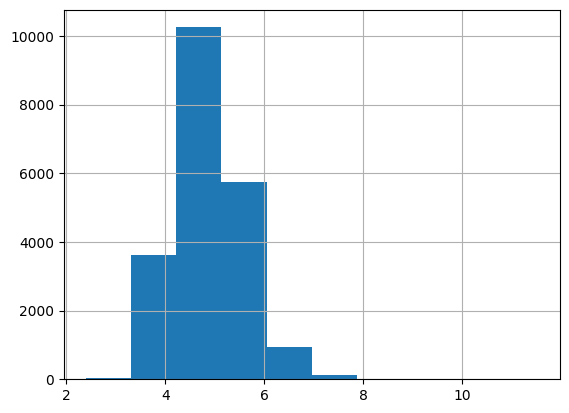

In [24]:
import numpy as np
y_log = np.log1p(y)
y_log.hist()

In [25]:
y_log.describe()

count    20745.000000
mean         4.875592
std          0.711063
min          2.397895
25%          4.394449
50%          4.836282
75%          5.298317
max         11.512936
Name: price, dtype: float64

In [26]:
from sklearn.compose import TransformedTargetRegressor

model_log = TransformedTargetRegressor(regressor=potok2, func=np.log1p, inverse_func=np.expm1)

In [27]:
wyniki_model_log = cross_validate(model_log, X_train, y_train, cv=5, scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error','r2'])
wyniki_model_log

c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:1

{'fit_time': array([0.64896441, 0.53161407, 0.48371744, 0.49028373, 0.5859158 ]),
 'score_time': array([0.02991486, 0.03235865, 0.03304625, 0.03622746, 0.03470707]),
 'test_neg_mean_absolute_error': array([-104.96019997,  -78.43593651, -107.61608975,  -73.73818837,
         -76.56854647]),
 'test_neg_root_mean_squared_error': array([-1746.93878909,  -297.33786753, -1758.4676853 ,  -231.49179814,
         -243.08569453]),
 'test_r2': array([0.00095977, 0.1280055 , 0.00165499, 0.16580259, 0.23006191])}

In [28]:
mae = - wyniki_model_log['test_neg_mean_absolute_error'].mean()
rmse = - wyniki_model_log['test_neg_root_mean_squared_error'].mean()
r2 = wyniki_model_log['test_r2'].mean()
print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 88.26379221412287
RMSE: 855.4643669189709
R2: 0.10529695241551647


In [29]:
do_tys = y_train <= 1000
X_train_1000 = X_train[do_tys]
y_train_1000 = y_train[do_tys]

In [30]:
len(X_train_1000), len(y_train_1000)

(16462, 16462)

In [31]:
wyniki_do_1000 = cross_validate(model_log, X_train_1000, y_train_1000, cv= 5, scoring=['neg_mean_absolute_error','neg_root_mean_squared_error','r2'])

c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:1

In [32]:
mae = - wyniki_do_1000['test_neg_mean_absolute_error'].mean()
rmse = - wyniki_do_1000['test_neg_root_mean_squared_error'].mean()
r2 = wyniki_do_1000['test_r2'].mean()

print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 61.8952189624207
RMSE: 106.3232172204993
R2: 0.36009042152341886


In [33]:
model_log.get_params().keys()

dict_keys(['check_inverse', 'func', 'inverse_func', 'regressor__memory', 'regressor__steps', 'regressor__transform_input', 'regressor__verbose', 'regressor__preprocessor', 'regressor__regressor', 'regressor__preprocessor__force_int_remainder_cols', 'regressor__preprocessor__n_jobs', 'regressor__preprocessor__remainder', 'regressor__preprocessor__sparse_threshold', 'regressor__preprocessor__transformer_weights', 'regressor__preprocessor__transformers', 'regressor__preprocessor__verbose', 'regressor__preprocessor__verbose_feature_names_out', 'regressor__preprocessor__num', 'regressor__preprocessor__cat', 'regressor__preprocessor__num__copy', 'regressor__preprocessor__num__with_mean', 'regressor__preprocessor__num__with_std', 'regressor__preprocessor__cat__categories', 'regressor__preprocessor__cat__drop', 'regressor__preprocessor__cat__dtype', 'regressor__preprocessor__cat__feature_name_combiner', 'regressor__preprocessor__cat__handle_unknown', 'regressor__preprocessor__cat__max_categori

In [34]:
parametry = {
    "regressor__regressor__n_estimators": [100, 200, 300],
    "regressor__regressor__max_depth": [5, 10, 20, None],
    "regressor__regressor__min_samples_leaf": [1, 5, 10]
}

In [35]:
from sklearn.model_selection import RandomizedSearchCV
search = RandomizedSearchCV(estimator= model_log,
                            param_distributions= parametry,
                            n_iter = 30,
                            scoring= 'neg_mean_absolute_error',
                            cv= 5,
                            random_state= 42)

In [36]:
search.fit(X_train, y_train)

c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:1

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",TransformedTa...egressor())]))
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'regressor__regressor__max_depth': [5, 10, ...], 'regressor__regressor__min_samples_leaf': [1, 5, ...], 'regressor__regressor__n_estimators': [100, 200, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscros

In [37]:
search.best_params_

{'regressor__regressor__n_estimators': 100,
 'regressor__regressor__min_samples_leaf': 10,
 'regressor__regressor__max_depth': 10}

In [38]:
-search.best_score_

np.float64(87.45325316607135)

In [39]:
search.fit(X_train_1000, y_train_1000)

c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:1

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",TransformedTa...egressor())]))
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'regressor__regressor__max_depth': [5, 10, ...], 'regressor__regressor__min_samples_leaf': [1, 5, ...], 'regressor__regressor__n_estimators': [100, 200, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscros

In [40]:
search.best_params_

{'regressor__regressor__n_estimators': 200,
 'regressor__regressor__min_samples_leaf': 5,
 'regressor__regressor__max_depth': 10}

In [41]:
-search.best_score_

np.float64(61.36380278163763)

In [42]:
best_model = search.best_estimator_

In [43]:
pred_train = best_model.predict(X_train_1000)

In [44]:
from sklearn.metrics import mean_absolute_error
mae_train = mean_absolute_error(y_train_1000, pred_train)
mae_train

59.88151050251978

In [45]:
parametr = {'n_estimators'   :  [10,20,50,100,150,200],
            'learning_rate'  :  [0.01,0.02,0.05,0.07,0.1],
            'max_depth'      :  [1,2,3,4,5,6,7,8,9],
             'min_samples_leaf' : [2, 5, 7, 9],
              'min_samples_split' : [2,5,7,9],
              'random_state' : [2,5,7]}


In [46]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
gradient = GradientBoostingRegressor(random_state= 42)
potok_gradient = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', gradient)
])




In [47]:
potok_gradient.fit(X_train_1000, y_train_1000)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformer

In [48]:
from sklearn.compose import TransformedTargetRegressor
model_boost = TransformedTargetRegressor(regressor=potok_gradient, func=np.log1p, inverse_func=np.expm1)


In [49]:
from sklearn.model_selection import cross_validate
wynik_boost = cross_validate(model_boost, X_train_1000, y_train_1000, cv = 5, scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error','r2'])

c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:1

In [50]:
wynik_boost

{'fit_time': array([0.54382563, 0.44776702, 0.37364006, 0.42345572, 0.43316674]),
 'score_time': array([0.01035714, 0.00683212, 0.00679159, 0.00736761, 0.00842404]),
 'test_neg_mean_absolute_error': array([-61.68656927, -62.00856943, -61.11194361, -62.09115451,
        -61.30699189]),
 'test_neg_root_mean_squared_error': array([-107.88989483, -108.38782412, -104.9268265 , -107.78669652,
        -102.41924735]),
 'test_r2': array([0.35094317, 0.34513   , 0.38281717, 0.35038056, 0.37409477])}

In [51]:
import numpy as np
np.mean(wynik_boost['fit_time'])


np.float64(0.44437103271484374)

In [52]:
np.mean(wynik_boost['test_neg_mean_absolute_error'])

np.float64(-61.64104574140576)

In [53]:
np.mean(wynik_boost['test_neg_root_mean_squared_error'])

np.float64(-106.2820978619432)

In [54]:
np.mean(wynik_boost['test_r2'])

np.float64(0.36067313436528237)

In [55]:
model_boost.get_params().keys()

dict_keys(['check_inverse', 'func', 'inverse_func', 'regressor__memory', 'regressor__steps', 'regressor__transform_input', 'regressor__verbose', 'regressor__preprocessor', 'regressor__regressor', 'regressor__preprocessor__force_int_remainder_cols', 'regressor__preprocessor__n_jobs', 'regressor__preprocessor__remainder', 'regressor__preprocessor__sparse_threshold', 'regressor__preprocessor__transformer_weights', 'regressor__preprocessor__transformers', 'regressor__preprocessor__verbose', 'regressor__preprocessor__verbose_feature_names_out', 'regressor__preprocessor__num', 'regressor__preprocessor__cat', 'regressor__preprocessor__num__copy', 'regressor__preprocessor__num__with_mean', 'regressor__preprocessor__num__with_std', 'regressor__preprocessor__cat__categories', 'regressor__preprocessor__cat__drop', 'regressor__preprocessor__cat__dtype', 'regressor__preprocessor__cat__feature_name_combiner', 'regressor__preprocessor__cat__handle_unknown', 'regressor__preprocessor__cat__max_categori

In [56]:
słownik = {
    'regressor__regressor__n_estimators': [100, 200, 500],
    'regressor__regressor__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'regressor__regressor__max_depth': [1, 2, 3, 4, 5],
    'regressor__regressor__min_samples_leaf': [1, 3, 5, 10]}

In [57]:
from sklearn.model_selection import RandomizedSearchCV
random_search = RandomizedSearchCV(estimator=model_boost, param_distributions=słownik, n_iter= 20, cv = 5, scoring= 'neg_mean_absolute_error', random_state= 42)

In [58]:
random_search.fit(X_train_1000, y_train_1000)

c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:1

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",TransformedTa..._state=42))]))
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'regressor__regressor__learning_rate': [0.01, 0.03, ...], 'regressor__regressor__max_depth': [1, 2, ...], 'regressor__regressor__min_samples_leaf': [1, 3, ...], 'regressor__regressor__n_estimators': [100, 200, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same 

In [59]:
random_search.best_params_

{'regressor__regressor__n_estimators': 200,
 'regressor__regressor__min_samples_leaf': 1,
 'regressor__regressor__max_depth': 5,
 'regressor__regressor__learning_rate': 0.03}

In [60]:
-random_search.best_score_

np.float64(61.32004062484812)

In [61]:
from sklearn.base import clone

najlepszy_boost = clone(model_boost)

In [62]:
najlepszy_boost.set_params(**{'regressor__regressor__n_estimators': 200,
 'regressor__regressor__min_samples_leaf': 1,
 'regressor__regressor__max_depth': 5,
 'regressor__regressor__learning_rate': 0.03})

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...m_state=42))])
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed ou

In [63]:
najlepszy_boost.fit(X_train_1000, y_train_1000)

c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(


,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...m_state=42))])
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed ou

In [64]:
pred_train = najlepszy_boost.predict(X_train_1000)

In [65]:
from sklearn.metrics import mean_absolute_error
mean_absolute_error(y_train_1000, pred_train)

60.025587175734856

In [66]:
from sklearn.model_selection import cross_validate
wynik_full = cross_validate(najlepszy_boost, X_train, y_train, cv= 5, scoring= ['neg_mean_absolute_error', 'r2', 'neg_root_mean_squared_error'])

c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:1

In [67]:
wynik_full['test_neg_mean_absolute_error'].mean()


np.float64(-87.18521845556403)

In [68]:

wynik_full['test_neg_root_mean_squared_error'].mean()

np.float64(-856.2444731969941)

In [69]:

wynik_full['test_r2'].mean()

np.float64(0.09968370200659067)

In [77]:
from sklearn.model_selection import RandomizedSearchCV
best_boost = RandomizedSearchCV(estimator= model_boost,
                                param_distributions= słownik,
                                n_iter = 30,
                                scoring= 'neg_mean_absolute_error',
                                cv= 5,
                                random_state= 42)
                

In [78]:
best_boost.fit(X_train, y_train)

c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:196: UserWarning: The provided functions are not strictly inverse of each other. If you are sure you want to proceed regardless, set 'check_inverse=False'.
  warnings.warn(
c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:1

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",TransformedTa..._state=42))]))
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'regressor__regressor__learning_rate': [0.01, 0.03, ...], 'regressor__regressor__max_depth': [1, 2, ...], 'regressor__regressor__min_samples_leaf': [1, 3, ...], 'regressor__regressor__n_estimators': [100, 200, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same 

In [79]:
-best_boost.best_score_

np.float64(87.18521845556403)

In [85]:
best_boost.best_params_

{'regressor__regressor__n_estimators': 200,
 'regressor__regressor__min_samples_leaf': 1,
 'regressor__regressor__max_depth': 5,
 'regressor__regressor__learning_rate': 0.03}

In [89]:
model = best_boost.best_estimator_

In [90]:
pred_test = model.predict(X_test)

In [ ]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
mae = mean_absolute_error(y_test, pred_test)
rmse = root_mean_squared_error(y_test, pred_test)
r2 = r2_score(y_test, pred_test)

In [94]:
mae

77.25076814239067

In [95]:
rmse

np.float64(106.3232172204993)

In [96]:
r2

np.float64(0.36009042152341886)

In [97]:
y_test.max()

np.float32(10000.0)

In [98]:
(y_test > 1000).sum()

np.int64(34)

In [99]:
y_train.max()

np.float32(100000.0)

In [100]:
import numpy as np 
bledy = np.abs(y_test - pred_test)

In [103]:
id_max = bledy.argmax()

In [104]:
y_test.iloc[id_max]

np.float32(10000.0)

In [105]:
pred_test[id_max]

np.float64(134.46380312028927)

In [106]:
bledy.iloc[id_max]

np.float64(9865.536196879711)

In [107]:
np.sqrt(np.mean(bledy ** 2))

np.float64(325.48807890509545)

In [108]:
len(y_test)
len(pred_test)

4149

In [109]:
mae_ofc = mean_absolute_error(y_test, pred_test)

In [111]:

from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
r2_ofc = r2_score(y_test, pred_test)

In [112]:
rmse_ofc = root_mean_squared_error(y_test, pred_test)

In [113]:
mae_ofc

77.25076814239067

In [114]:
r2_ofc

0.09216933172936359

In [115]:
rmse_ofc

325.48807890509545

In [116]:
import joblib
joblib.dump(model, "airbnb_price_model.pkl")

['airbnb_price_model.pkl']

In [117]:
loaded_model = joblib.load("airbnb_price_model.pkl")

In [119]:
pred_loaded = loaded_model.predict(X_test)

In [120]:
np.allclose(pred_test, pred_loaded)

True